In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [23]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import  astropy.io.ascii as ascii
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask_fdeltacut/'
pltDir=os.path.join(anaDir,'plot/selBias/')
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


# Selection Bias of Resolution Cut
## Preparation

Read data and apply weak lensing. 90 degree rotation is applied for cuts except the resolution cut.

In [3]:
# Read catalog
dataP =   pd.read_hdf(inFname,mode='r')
data=dataP.to_records()

In [6]:
min_snr=10
max_snr=None
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask2    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=False,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataU2=data[wlmask2]
weight2=utilities.get_weight_model(dataU2)*dataU2['weight']

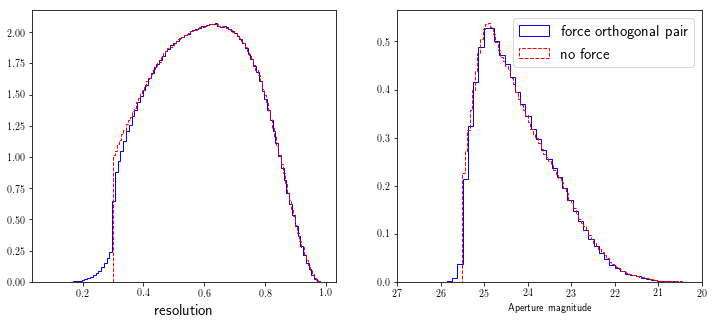

In [7]:
if True:
    min_snr=10
    max_snr=None
    max_magA10=25.5
    min_res=0.3
    max_mag=24.5
    max_logb=-0.38
    max_sigma_e=0.4
    max_e=2.

    wlmask    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=True,
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    dataU=data[wlmask]
    weight=utilities.get_weight_model(dataU)*dataU['weight']
    
    # 
    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(1,2,1)

    ax.hist(dataU['res'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
    ax.hist(dataU2['res'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
    ax.set_xlabel('resolution',fontsize=15)

    ax = fig.add_subplot(1,2,2)
    ax.hist(dataU['magA10'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
    ax.hist(dataU2['magA10'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
    ax.set_xlim(27,20)
    ax.set_xlabel('Aperture magnitude')
    plt.legend(fontsize=15,loc='upper right')
    plt.savefig(os.path.join(pltDir,'selBias_PDF_90rot_no90rot.eps'))
    plt.savefig(os.path.join(pltDir,'selBias_PDF_90rot_no90rot.png'))

In [11]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,dataU,doPlot=False):
    nbin_1d=5
    shape_weight = utilities.get_weight_model(dataU)*dataU['weight']
    p_edges=np.zeros(nbin_1d)

    if obsname=="mag":
        xlabel='Cmodel Magnitude (lower limit)'
        cutplace=r'\rm{mag}=24.5'
        obs_cuts  =   np.linspace(20,22.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 24.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="magA10":
        xlabel='Aperture Magnitude (lower limit)'
        cutplace=r'\rm{magA}=25.5'
        obs_cuts  =   np.linspace(23,24.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 25.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="res":
        xlabel='Regaus resolution (upper limit)'
        cutplace=r'\rm{res}=0.3'
        obs_cuts  =   np.linspace(0.5,1.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.01
        n_first_bin = np.sum(shape_weight[(obs <= 0.3 + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)
    elif obsname=="snr":
        xlabel='Cmodel SNR (upper limit)'
        cutplace=r'\rm{snr}=10'
        obs_cuts  =   np.linspace(80.,200.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   1.
        n_first_bin = np.sum(shape_weight[(obs <= 10. + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)

    print(p_edges)
    shearBinName1=   os.path.join(pltDir,'shear_selbias_%s_%s.npy' %(obsname,obsname))
    shearBinName2=   os.path.join(pltDir,'shear_selbias_%s_%s_90rot.npy' %(obsname,obsname))

    m1,a1,sigm1,siga1=get_mc_bins(shearBinName1,nbin_1d)
    m2,a2,sigm2,siga2=get_mc_bins(shearBinName2,nbin_1d)

    if doPlot:
        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(obs_cuts, m1-m2,sigm1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)
        ax.set_title('Multiplicative bias')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(obs_cuts, a1-a2,siga1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)
        ax.set_title('Additive bias')
        plt.grid()
        plt.tight_layout()
        #plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(obs_cuts, (m1-m2)/p_edges,sigm1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$m_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Multiplicative bias of selection')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(obs_cuts, (a1-a2)/p_edges,siga1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$a_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Additive bias of selection')
        plt.grid()
        plt.tight_layout()
        plt.savefig(os.path.join(pltDir,'selBias_%s.eps' %(obsname)))
    return obs_cuts,m1-m2,sigm1*np.sqrt(2.),a1-a2,siga1*np.sqrt(2.), p_edges

[0.24006924 0.26212607 0.29758285 0.35871524 0.4827677 ]


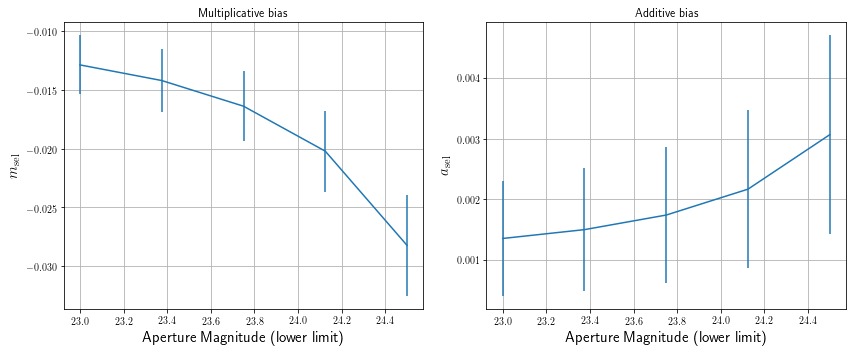

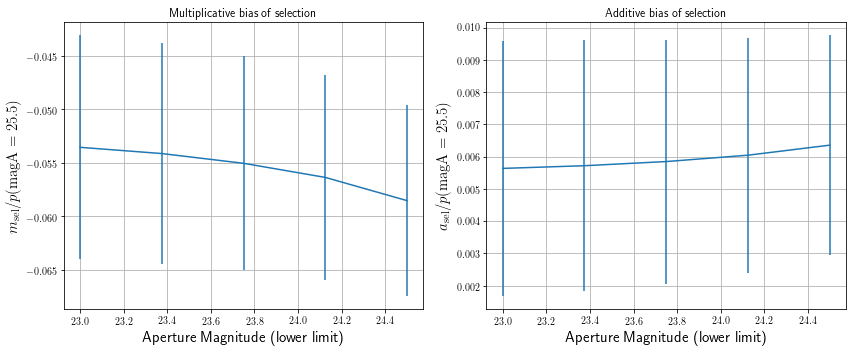

In [12]:
grid1,m_res1,sigm1,a_res1,siga1,pedge1=makePlotSelBias('magA10',dataU2,doPlot=True)

[3.38833071 1.85373922 1.27756515 1.05668215 1.02502921]


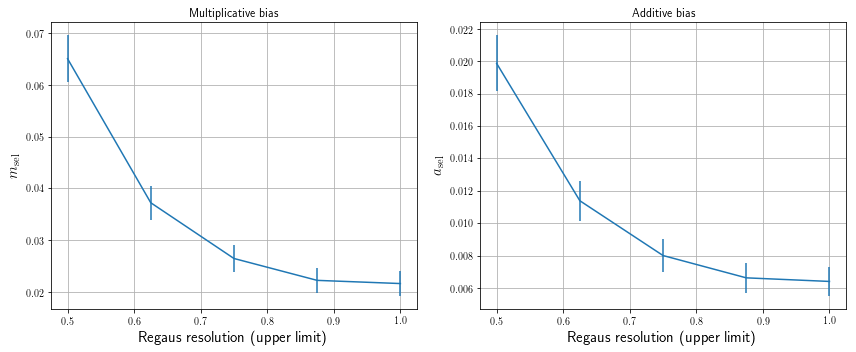

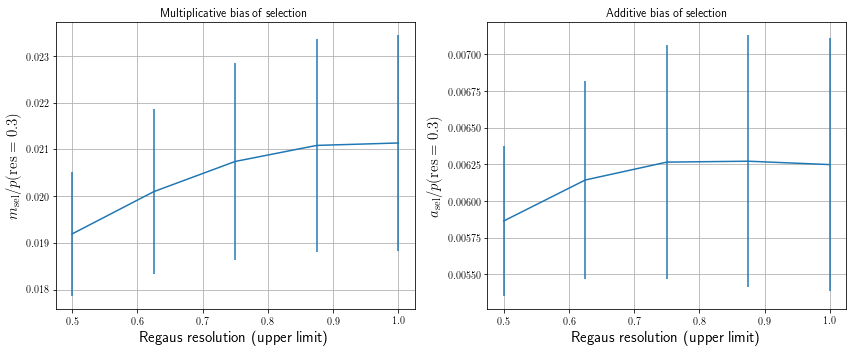

In [13]:
grid2,m_res2,sigm2,a_res2,siga2,pedge2=makePlotSelBias('res',dataU2,doPlot=True)

In [15]:
print('magA')
print(m_res1)
print(a_res1)
print('res')
print(m_res2)
print(a_res2)

magA
[-0.01310948 -0.01412934 -0.01565832 -0.01795382 -0.02171287 -0.02872233]
[0.00132326 0.00143041 0.00159022 0.001835   0.00223788 0.00298838]
res
[0.06302315 0.03944105 0.02878453 0.023506   0.02133977 0.02104806]
[0.02312014 0.01456587 0.0105749  0.00852013 0.00764595 0.00752119]


In [14]:
print('magA')
print(m_res1)
print(a_res1)
print('res')
print(m_res2)
print(a_res2)

magA
[-0.01285461 -0.014189   -0.01638004 -0.02021942 -0.02826246]
[0.0013529  0.00149899 0.0017401  0.00216813 0.00306817]
res
[0.06502895 0.03725068 0.02649853 0.02227961 0.02166545]
[0.0198663  0.01138638 0.00800294 0.00662577 0.00640366]


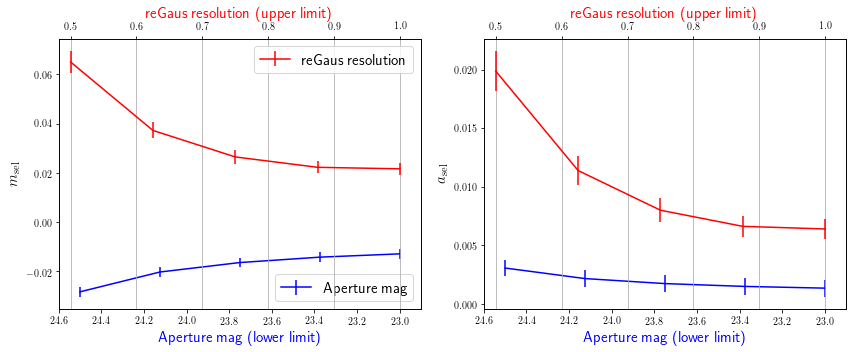

In [28]:
label1='Aperture mag'
label2='reGaus resolution'

fig = plt.figure(figsize=(12,5))

ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1,m_res1,sigm1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)
ax1.legend(fontsize=15,loc='lower right')
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2,sigm2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
ax2.legend(fontsize=15,loc='upper right')
plt.grid()


ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1, a_res1,siga1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2,siga2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_res_magA10.eps'))

In [16]:
print('magA')
print('m')
print(m_res1/pedge1)
print(np.average(m_res1/pedge1))
print('a')
print(a_res1/pedge1)
print(np.average(a_res1/pedge1))
print('res')
print('m')
print(m_res2/pedge2)
print(np.average(m_res2/pedge2))
print('a')
print(a_res2/pedge2)
print(np.average(a_res2/pedge2))

magA
m
[-0.05354541 -0.05413045 -0.05504362 -0.05636621 -0.05854258]
-0.055525653470591664
a
[0.00563546 0.00571859 0.00584745 0.00604416 0.00635538]
0.005920206380492709
res
m
[0.01919203 0.02009489 0.02074143 0.02108449 0.02113642]
0.020449853253127696
a
[0.00586315 0.00614238 0.00626421 0.00627035 0.0062473 ]
0.0061574802606778915


In [18]:
shape_weight = utilities.get_weight_model(dataU2)*dataU2['weight']

In [25]:
bin_size  =   0.1
pedge1f=np.sum(shape_weight[(utilities.get_imag_A10(dataU2) >= 25.5 - bin_size)])/np.sum(shape_weight)/bin_size
print(pedge1f*-0.0585)
print(pedge1f*0.00636)

-0.014224227901156194
0.0015464288795103145


In [26]:
bin_size  =   0.01
pedge2f=np.sum(shape_weight[(utilities.get_res(dataU2) <= 0.3 + bin_size)])/np.sum(shape_weight)/bin_size
print(pedge2f*0.0192)
print(pedge2f*0.00615)

0.019680560824089553
0.006303929638966185


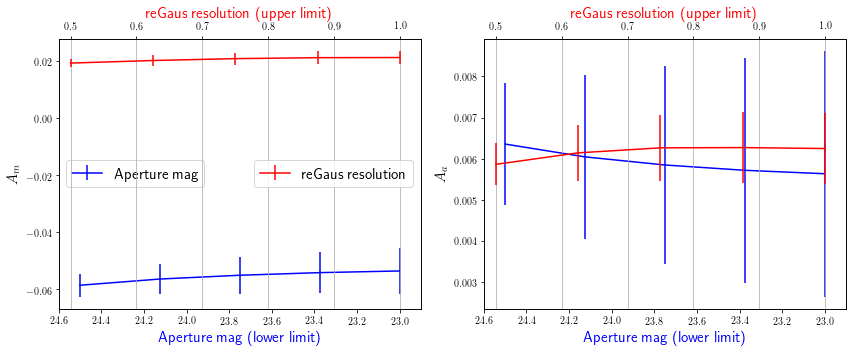

In [29]:
label1='Aperture mag'
label2='reGaus resolution'

fig = plt.figure(figsize=(12,5))


ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1, m_res1/pedge1,sigm1/pedge1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$A_{m}$',fontsize=15)
ax1.set_xlim(24.6,22.9)
ax1.legend(fontsize=15,loc='center left')

ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2/pedge2,sigm2/pedge2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')
ax2.legend(fontsize=15,loc='center right')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
plt.grid()



ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1, a_res1/pedge1,siga1/pedge1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$A_{a}$',fontsize=15)
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2/pedge2,siga2/pedge2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_ratio_res_magA10.eps'))

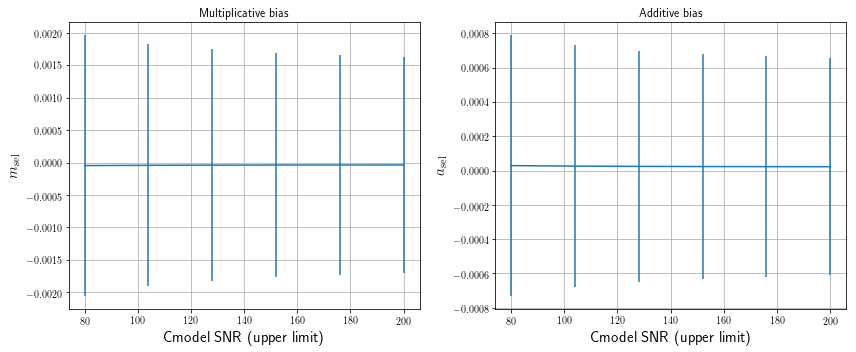

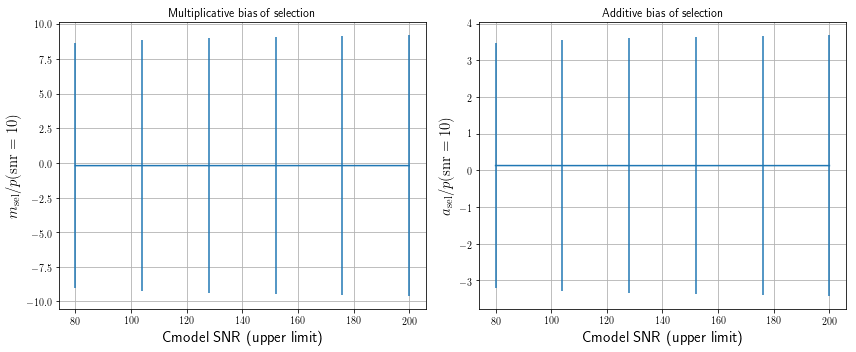

In [36]:
makePlotSelBias('snr',dataU2,doPlot=True)

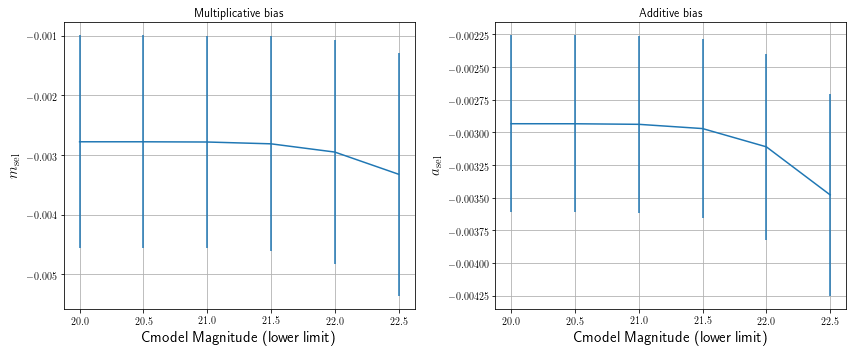

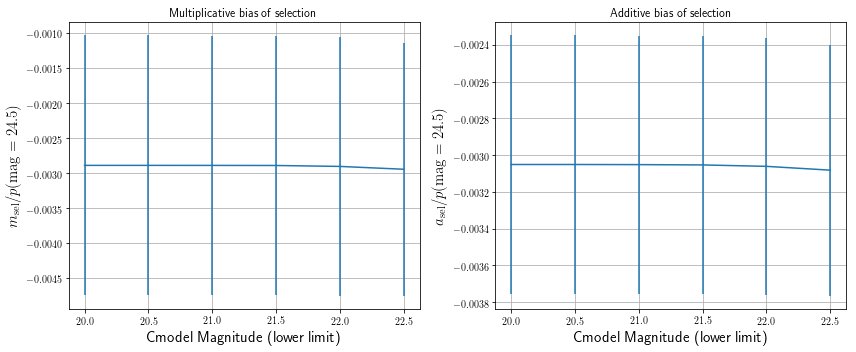

In [37]:
makePlotSelBias('mag',dataU2,doPlot=True)

## S16A Estimation
$$A= 0.00865\pm 0.0026$$

In [27]:
dataP2=dataP[wlmask2&(~np.isnan(dataP['mizuki_Z']))]

indexS=  dataP.index.levels[1]
indexList= ascii.read('info_newS19Mask_fd001_sim.csv')['num']
mask=np.in1d(indexList,indexS)
indexList=indexList[mask]

outData=[]
for index in indexList:
    catalog =   dataP2.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m = utilities.get_m_model(catalog,weight_bias=True,photo_z_dep=True)

    model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=True,photo_z_dep=True)
    model_c1+=psf_e1*0.008
    model_c2+=psf_e2*0.008
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight+0.005
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)
    
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0081 +/- 0.0019
a = 0.0038 +/- 0.0007
